# Chatbot

In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph,START,END

from langgraph.graph.message import add_messages

import os
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
class State(TypedDict):
    # messages have the type "List". the `add_messages` function in the annotation
    # defines how this state key should be updated when a new message is added to the graph.
    # in this case we are using the `add_messages` function to append new messages to the existing list of messages.
    messages: Annotated[list,add_messages]



### DEFINING THE LLM

In [3]:
from langchain_ollama import ChatOllama
llm = ChatOllama(
    model="qwen3:8b",
    base_url= os.getenv("OLLAMA_API_KEY"),
)

#### SQL TOOL

In [4]:
from langgraph.prebuilt import ToolNode,tools_condition

In [5]:
# Cell 2: Inspect the table schema
import psycopg
from psycopg.rows import dict_row
from urllib.parse import urlparse, parse_qs


DATABASE_URL = os.getenv("DATABASE_URL")
# Replace this when you provide your actual table name.
TABLE_NAME = "scraped_bonds"

def get_connection():
    return psycopg.connect(
        DATABASE_URL,
        row_factory=dict_row,
        connect_timeout=10,
    )

def get_table_schema(table_name: str) -> list[dict]:
    parsed_url = urlparse(DATABASE_URL)
    schema_name = parse_qs(parsed_url.query).get("schema", ["public"])[0]

    query = """
        SELECT column_name, data_type, is_nullable
        FROM information_schema.columns
        WHERE table_schema = %s
          AND table_name = %s
        ORDER BY ordinal_position
    """

    with get_connection() as conn:
        with conn.cursor() as cursor:
            cursor.execute(query, (schema_name, table_name))
            columns = cursor.fetchall()

    if not columns:
        raise ValueError(f"Could not find table {schema_name}.{table_name}.")

    return columns

table_schema = get_table_schema(TABLE_NAME)
table_schema

[{'column_name': 'source_url', 'data_type': 'text', 'is_nullable': 'NO'},
 {'column_name': 'final_url', 'data_type': 'text', 'is_nullable': 'YES'},
 {'column_name': 'fetched_at',
  'data_type': 'timestamp with time zone',
  'is_nullable': 'NO'},
 {'column_name': 'isin', 'data_type': 'text', 'is_nullable': 'NO'},
 {'column_name': 'issuer_name', 'data_type': 'text', 'is_nullable': 'YES'},
 {'column_name': 'ytm_percent', 'data_type': 'numeric', 'is_nullable': 'YES'},
 {'column_name': 'coupon_percent',
  'data_type': 'numeric',
  'is_nullable': 'YES'},
 {'column_name': 'minimum_investment_inr',
  'data_type': 'numeric',
  'is_nullable': 'YES'},
 {'column_name': 'face_value_inr',
  'data_type': 'numeric',
  'is_nullable': 'YES'},
 {'column_name': 'issue_date', 'data_type': 'date', 'is_nullable': 'YES'},
 {'column_name': 'maturity_date', 'data_type': 'date', 'is_nullable': 'YES'},
 {'column_name': 'bond_status', 'data_type': 'text', 'is_nullable': 'YES'},
 {'column_name': 'is_active', 'data_

In [6]:
# Cell 3: Add the read-only query tool
import re
from langchain.tools import tool

@tool
def query_database(sql: str) -> str:
    """Run one read-only SELECT query against the configured PostgreSQL table.

    Use this tool to answer questions about records in the database.
    Only query the configured table and its columns. Do not modify data.
    """

    sql = sql.strip().rstrip(";")

    if not re.match(r"^(SELECT|WITH)\b", sql, flags=re.IGNORECASE):
        return "Rejected: only SELECT queries are allowed."

    # Reject multiple statements and SQL comment markers.
    if ";" in sql or "--" in sql or "/*" in sql:
        return "Rejected: multiple statements and SQL comments are not allowed."

    # Prevent an unexpectedly large result.
    if not re.search(r"\bLIMIT\s+\d+\b", sql, flags=re.IGNORECASE):
        sql += " LIMIT 100"

    try:
        with get_connection() as conn:
            conn.execute("SET TRANSACTION READ ONLY")
            with conn.cursor() as cursor:
                cursor.execute(sql)
                rows = cursor.fetchall()
                return str(rows)
    except Exception as exc:
        return f"Query failed: {exc}"

#### SYSTEM PROMPT

In [7]:
system_prompt = f"""
You are a read-only assistant for bond data stored in the PostgreSQL table
"{TABLE_NAME}". Answer questions using this table and the query_database tool.

Available columns:
{table_schema}

HOW TO USE THE DATABASE
- For questions about a bond, issuer, company, bond status, yield, or other
  database records, call query_database before answering. Do not guess or rely
  on general knowledge for database facts.
- for multi-step questions, you may call query_database multiple times to gather the
  necessary information before answering. so make multiple queries if needed and call the tool multiple times.
- Generate SQL using only the table "{TABLE_NAME}" and the columns listed above.
- Use SELECT queries only. Never attempt to insert, update, delete, or alter data.
- Do not show SQL, tool instructions, or internal reasoning to the user.

SEARCH RULES
- For an ISIN search, match the isin column exactly when the user provides a
  complete ISIN.
- For an issuer or company name, search issuer_name with a case-insensitive
  partial match, for example: issuer_name ILIKE '%navi finserv%'.
- If the first search returns no result, you may retry once with a simpler
  partial issuer name or a relevant alternative listed in the user's question.
- Do not claim that two records are the same unless the returned data supports it.

RESULT RULES
- Strictly no personalised financial advice. Do not recommend specific bonds or investment actions.
- For a question about a specific bond, include its source_url in the answer
  whenever that column is available and returned by the query.
- If the user asks about returns or yield, include ytm_percent whenever that
  column is available and returned by the query. Do not describe YTM as a
  guaranteed return.
- If the user asks for all active bonds, count records whose bond_status is
  exactly 'Invest Now'. Return the count and, if useful, a concise list of the
  matching bonds.
- For other questions, select only the columns needed to answer them.
- If multiple records match, say so and distinguish them using relevant fields
  such as issuer, ISIN, maturity, or status. Do not silently choose one.
- If no matching record is found after searching, say that no matching record
  was found in the database.

RESPONSE STYLE
- Be direct and clear. Summarize the database result in ordinary language.
- Preserve the values and wording returned by the database; do not invent
  missing details.
- If a requested field is absent or was not returned, say that it is unavailable
  in the retrieved record.

SQL TOOL USAGE GUIDE

Available tool: query_database(sql)
Purpose: Execute one read-only SQL query against the configured PostgreSQL table.

When to call it:
- Call the tool for any question that asks about database records, including
  bonds, issuers, ISINs, status, yields, counts, or comparisons.
- Do not call it for general explanations that do not depend on database data.
- For a database question, retrieve the relevant data before answering.

MULTI-STEP DATABASE QUESTIONS

- A single user question may require multiple database queries.
- You are allowed to call query_database multiple times during one user request.
- Do not assume that one SQL query must be sufficient.
- If the question contains multiple independent requirements, retrieve the
  necessary data for each requirement before answering.
- After receiving a tool result, inspect it and decide whether another query
  is necessary.
- You may perform sequential query_database calls when the result of one query
  informs the next query.
- Do not combine unrelated queries into one SQL statement merely to reduce
  tool calls.
- Continue querying until you have enough database evidence to answer all
  parts of the user's question.
- Then provide one consolidated answer to the user.

How to build a query:
- Use only SELECT statements and the configured table "{TABLE_NAME}".
- Use only the columns listed in the schema above.
- Use single quotes around text values.
- For a complete ISIN, filter the isin column by exact match.
- For an issuer or company name, use a case-insensitive partial match on
  issuer_name with ILIKE, for example:
  SELECT * FROM "{TABLE_NAME}"
  WHERE issuer_name ILIKE '%navi finserv%'
- For active bond counts, filter bond_status to 'Invest Now' and use COUNT(*).
- Select only the columns needed to answer the question. Include source_url for
  bond-specific answers and ytm_percent when the user asks about yield or returns.
- Add a reasonable LIMIT when returning a list of records. The tool adds LIMIT
  100 automatically if one is not provided.
- Submit one SQL statement per tool call. Do not include a trailing second
  statement, SQL comments, or data-changing commands.

After the tool returns:
- Base the answer only on the returned rows.
- Explain the result in clear, concise language; do not show the SQL.
- If several rows match, distinguish them using fields such as issuer, ISIN,
  maturity, or status.
- If no rows match, say that no matching record was found. You may retry once
  with a simpler partial issuer name when that could resolve the search.
- If the query fails, do not invent an answer. Briefly explain that the database
  query failed.

RECOMMENDATIONS BY YIELD AND MATURITY

When the user asks for bond recommendations with a minimum yield and a maximum
time to maturity—for example, “recommend me a bond with a yield of at least 8%
and a maturity of less than 5 years”—follow these steps:

1. Use the current date as the reference date. Do not assume a fixed date.
2. Check the schema above for the columns containing bond status, yield (YTM),
   and maturity date. Use the actual column names and data types shown there.
3. Retrieve only bonds that are active now. Use bond_status = 'Invest Now' as
   the active-bond filter.
4. Apply the requested minimum yield to ytm_percent. For “at least 8%”, use
   ytm_percent >= 8, assuming the column stores percentages on a 0–100 scale.
   If the schema or stored values indicate a different scale, adapt the
   comparison accordingly.
5. Calculate time to maturity from the current date to each bond’s maturity
   date. For “less than 5 years”, include only bonds whose maturity date is
   later than the current date and whose maturity date is before the date five
   calendar years from today. Do not approximate five years as 1,825 days.
6. Include the bond name or issuer, ISIN, YTM, maturity date, calculated time
   remaining, and source_url in the results when those columns are available.
7. If the user’s criteria produce no active matches, say so. Do not recommend
   inactive, matured, or otherwise non-matching bonds as alternatives without
   clearly identifying that they do not meet the stated criteria.
8. Explain that YTM is a database-reported yield measure and should not be
   presented as a guaranteed return.
9. Give the remaining time in years months and days, for example: “This bond has 3 years, 2 months, and 15 days remaining until maturity.”
10. . A bond is investable now if it is marked as active (is_active = true), has an active bond_status, has already been issued (issue_date <= today), and has not yet matured (maturity_date > today). The COUNT aggregate returns a single meaningful number.
Build the date and yield filters into the SQL query where possible. Use the
database’s current date for filtering (CURRENT_DATE), so the active maturity
window is evaluated when the query runs. After retrieving the matching rows,
calculate and report the remaining time to maturity in clear language. Never
invent a maturity date, yield, or calculated duration.

"""

#### BINDING LLM WITH TOOLS

In [8]:
tools = [query_database]

In [9]:
llm_with_tools = llm.bind_tools(tools)

### DEFINING STATE AND CHAT 

In [10]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

In [11]:
def chatbot(state: State):
    messages = [SystemMessage(content=system_prompt)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

In [19]:
graph_builder = StateGraph(State)

graph_builder.add_node("llmchatbot", chatbot)
graph_builder.add_node("tool", ToolNode(tools))

graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_conditional_edges(
    "llmchatbot",
    tools_condition,
    {"tools": "tool", END: END},
)
graph_builder.add_edge("tool", "llmchatbot")

graph = graph_builder.compile(checkpointer=memory)

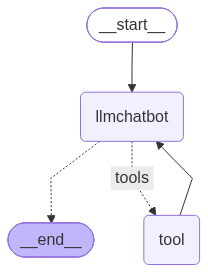

In [22]:
from IPython.display import display, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [23]:
config = {"configurable": {"thread_id": "1"}}

In [ ]:
response = graph.invoke({"messages": ["What can you do?"
""]},config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

hi
================================== Ai Message ==================================

Hello! How can I assist you today? I can provide information about bonds, issuers, yields, and other related data from my database. Just let me know your query!


#### 

#### Streaming

methods .stream() and astream()

additional parameters : values and updates.

In [29]:
for chunk in graph.stream(
    {"messages": ["Hi"]},
    config=config,
    stream_mode="updates"
):
    print(chunk)

{'llmchatbot': {'messages': [AIMessage(content='Hello! How can I assist you today?', additional_kwargs={}, response_metadata={'model': 'qwen3:8b', 'created_at': '2026-10-13T07:22:40.599349483Z', 'done': True, 'done_reason': 'stop', 'total_duration': 3649839797, 'load_duration': 414840791, 'prompt_eval_count': 2406, 'prompt_eval_duration': 272743000, 'eval_count': 104, 'eval_duration': 2936132000, 'logprobs': None, 'model_name': 'qwen3:8b', 'model_provider': 'ollama'}, id='lc_run--01a13424-4e12-7940-84ac-ca81e79c4917-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 2406, 'output_tokens': 104, 'total_tokens': 2510})]}}
